In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel('./data/xuemeng_for_res/predicted_chat_log.xlsx', sheet_name=0, header=None)
print(df.head(6))

df = df.drop(index=0)
df.columns = ["id", "time", "user", "type", "content", "emotion"]

   0                    1               2        3           4      5
0  0                    1               2        3           4      5
1  1  2025-09-09 15:16:54   自爆法蒂瑪要od花刀雙子塔   type_2  艾特我看小猫绝美侧颜  happy
2  2  2025-09-09 15:16:54   自爆法蒂瑪要od花刀雙子塔   type_2  艾特我看小猫绝美侧颜  happy
3  3  2025-09-09 15:20:13            桂仁蒸叶   type_2   多pre一下就好了    sad
4  4  2025-09-09 15:20:14  Waldeinsamkeit   type_2     口语一点都不会  angry
5  6  2025-09-09 15:20:16  Waldeinsamkeit  type_17      [[大哭]]    sad


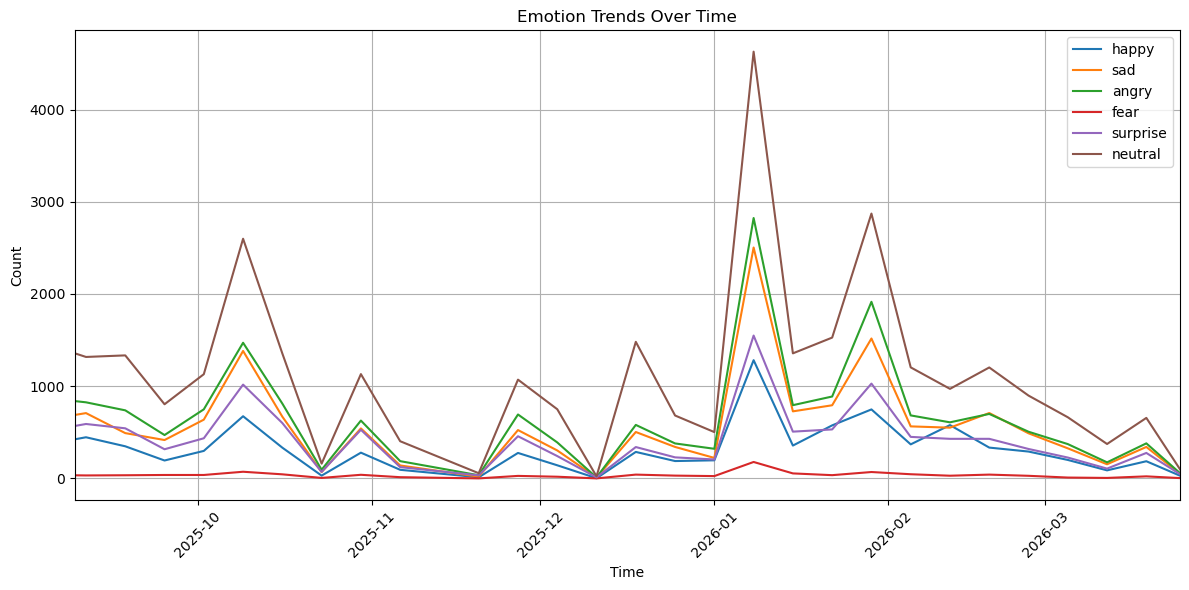

In [59]:
df["time"] = pd.to_datetime(df["time"])
df["time_bin"] = df["time"].dt.floor("7D")

pivot = df.pivot_table(
    index="time_bin",
    columns="emotion",
    aggfunc="size",
    fill_value=0,
    sort=False
)

pivot = pivot.sort_index()
plt.figure(figsize=(12, 6))

for col in pivot.columns:
    plt.plot(pivot.index, pivot[col], label=col)
    
plt.xlim(pd.Timestamp('2025-09-09'), pd.Timestamp('2026-03-25'))
plt.grid(True)
plt.xlabel("Time")
plt.ylabel("Count")
plt.title("Emotion Trends Over Time")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

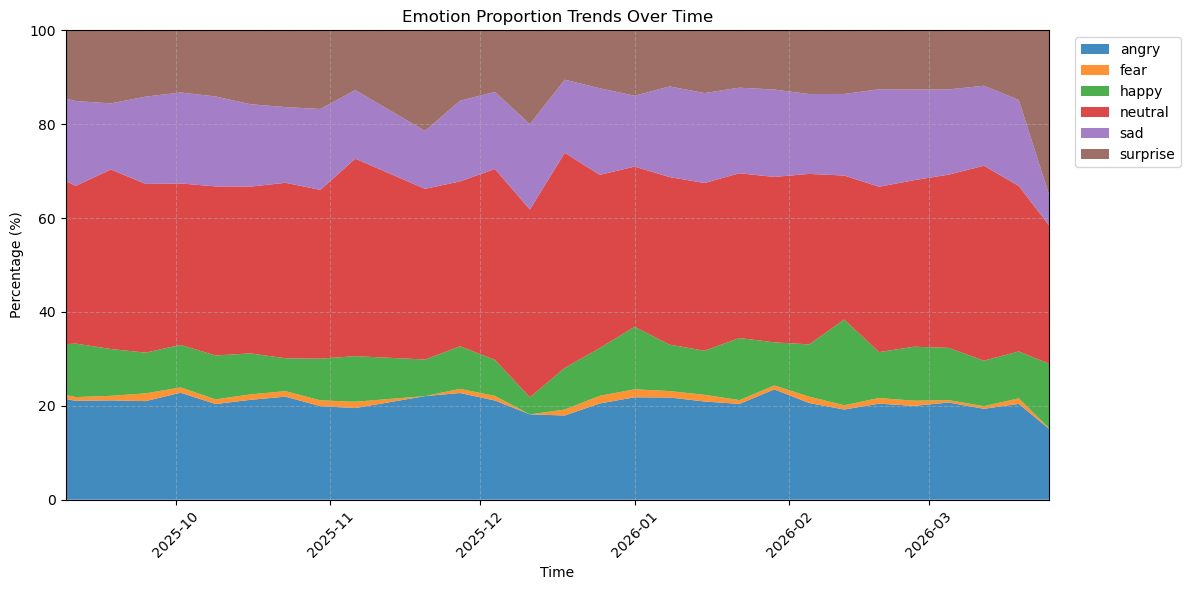

In [3]:
df["time"] = pd.to_datetime(df["time"])
df["time_bin"] = df["time"].dt.floor("7D")

pivot = df.pivot_table(
    index="time_bin",
    columns="emotion",
    aggfunc="size",
    fill_value=0,
)
pivot = pivot.sort_index()

pivot_perc = pivot.div(pivot.sum(axis=1), axis=0) * 100

plt.figure(figsize=(12, 6))

plt.stackplot(pivot_perc.index, pivot_perc.T, labels=pivot_perc.columns, alpha=0.85)

plt.xlim(pd.Timestamp('2025-09-09'), pd.Timestamp('2026-03-25'))
plt.ylim(0, 100)

plt.grid(True, linestyle='--', alpha=0.5)
plt.xlabel("Time")
plt.ylabel("Percentage (%)")
plt.title("Emotion Proportion Trends Over Time")
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()